In [1]:
import pandas as pd

df = pd.read_csv("data/Bankruptcy_prevention_Dataset.csv", sep=";", skipinitialspace=True)
df.columns = df.columns.str.strip()
print(df.shape)
df.head()

(250, 7)


,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk,class
0,0.5,1.0,0.0,0.0,0.0,0.5,bankruptcy
1,0.0,1.0,0.0,0.0,0.0,1.0,bankruptcy
2,1.0,0.0,0.0,0.0,0.0,1.0,bankruptcy
3,0.5,0.0,0.0,0.5,0.0,1.0,bankruptcy
4,1.0,1.0,0.0,0.0,0.0,1.0,bankruptcy


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
%matplotlib inline

In [3]:
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.info()

Shape: (250, 7)

Columns: ['industrial_risk', 'management_risk', 'financial_flexibility', 'credibility', 'competitiveness', 'operating_risk', 'class']

Missing values:
 industrial_risk          0
management_risk          0
financial_flexibility    0
credibility              0
competitiveness          0
operating_risk           0
class                    0
dtype: int64

Duplicate rows: 147
<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   industrial_risk        250 non-null    float64
 1   management_risk        250 non-null    float64
 2   financial_flexibility  250 non-null    float64
 3   credibility            250 non-null    float64
 4   competitiveness        250 non-null    float64
 5   operating_risk         250 non-null    float64
 6   class                  250 non-null    str    
dtypes: float64(6), str(1)
memory usage: 16.8 K

In [4]:
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))
print("\nMissing values:\n", df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.info()

Shape: (250, 7)

Columns: ['industrial_risk', 'management_risk', 'financial_flexibility', 'credibility', 'competitiveness', 'operating_risk', 'class']

Missing values:
 industrial_risk          0
management_risk          0
financial_flexibility    0
credibility              0
competitiveness          0
operating_risk           0
class                    0
dtype: int64

Duplicate rows: 147
<class 'pandas.DataFrame'>
RangeIndex: 250 entries, 0 to 249
Data columns (total 7 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   industrial_risk        250 non-null    float64
 1   management_risk        250 non-null    float64
 2   financial_flexibility  250 non-null    float64
 3   credibility            250 non-null    float64
 4   competitiveness        250 non-null    float64
 5   operating_risk         250 non-null    float64
 6   class                  250 non-null    str    
dtypes: float64(6), str(1)
memory usage: 16.8 K

In [5]:
df.describe()

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
count,250.000000,250.000000,250.000000,250.000000,250.000000,250.000000
mean,0.518000,0.614000,0.376000,0.470000,0.476000,0.570000
std,0.411526,0.410705,0.401583,0.415682,0.440682,0.434575
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.500000,0.000000,0.000000,0.000000,0.000000
50%,0.500000,0.500000,0.500000,0.500000,0.500000,0.500000
75%,1.000000,1.000000,0.500000,1.000000,1.000000,1.000000
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


class
non-bankruptcy    143
bankruptcy        107
Name: count, dtype: int64
class
non-bankruptcy    0.57
bankruptcy        0.43
Name: proportion, dtype: float64


C:\Users\gunja\AppData\Local\Temp\ipykernel_20392\2412537141.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="class", data=df, palette="Set2")


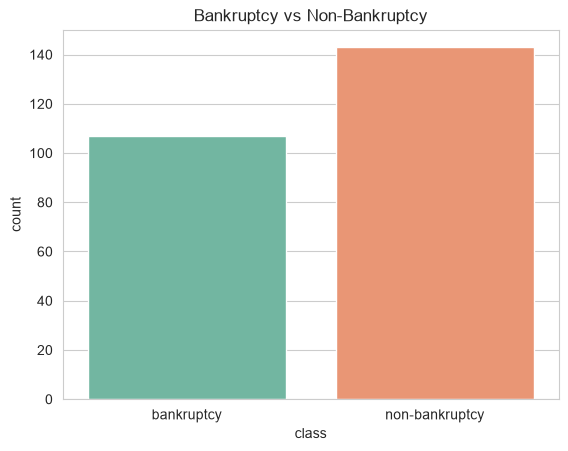

In [6]:
print(df["class"].value_counts())
print(df["class"].value_counts(normalize=True).round(2))

sns.countplot(x="class", data=df, palette="Set2")
plt.title("Bankruptcy vs Non-Bankruptcy")
plt.show()

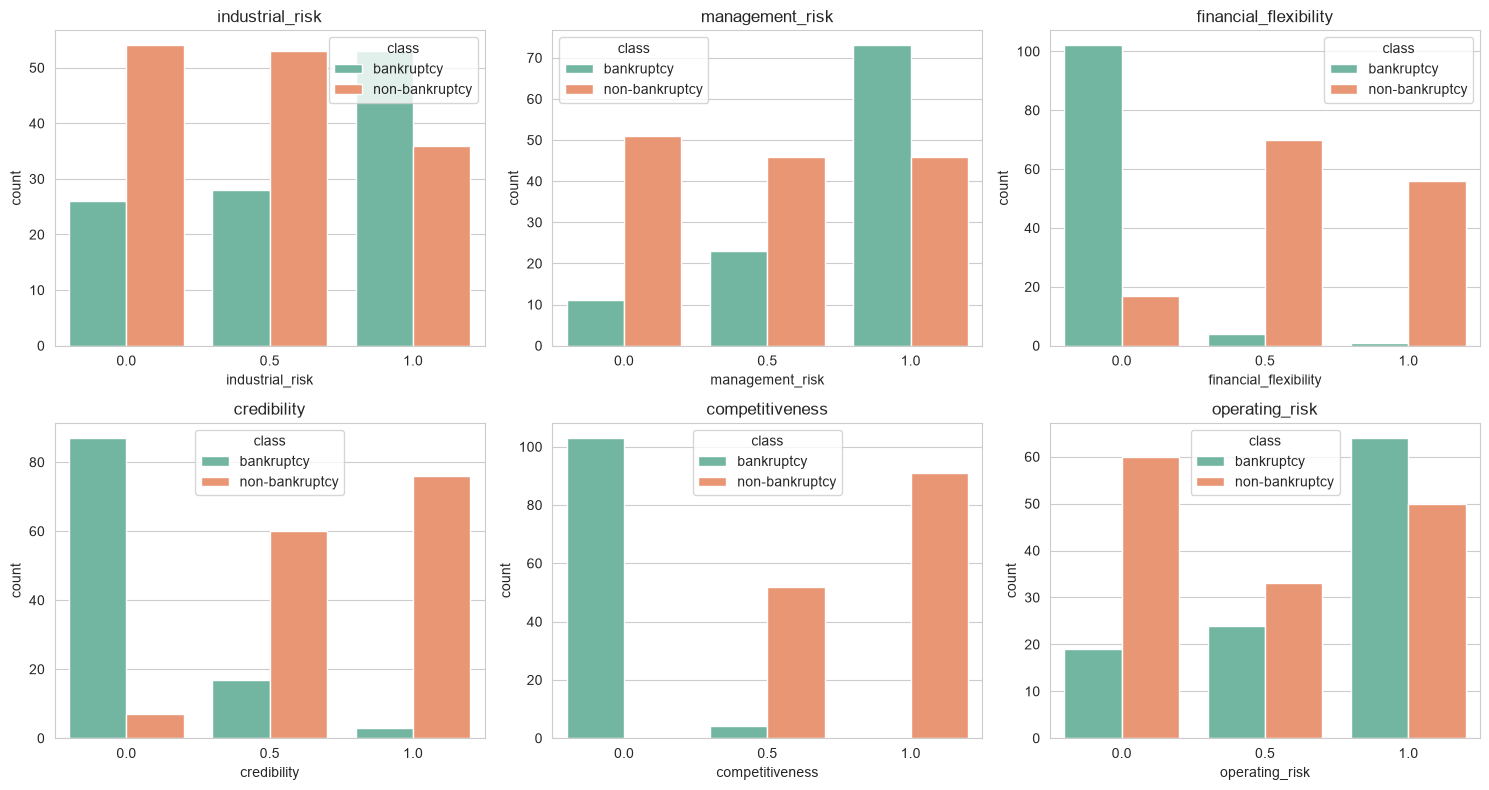

In [7]:
features = df.columns[:-1]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flatten(), features):
    sns.countplot(x=col, hue="class", data=df, palette="Set2", ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [8]:
df.groupby("class").mean().round(2)

,industrial_risk,management_risk,financial_flexibility,credibility,competitiveness,operating_risk
class,,,,,,
bankruptcy,0.63,0.79,0.03,0.11,0.02,0.71
non-bankruptcy,0.44,0.48,0.64,0.74,0.82,0.47


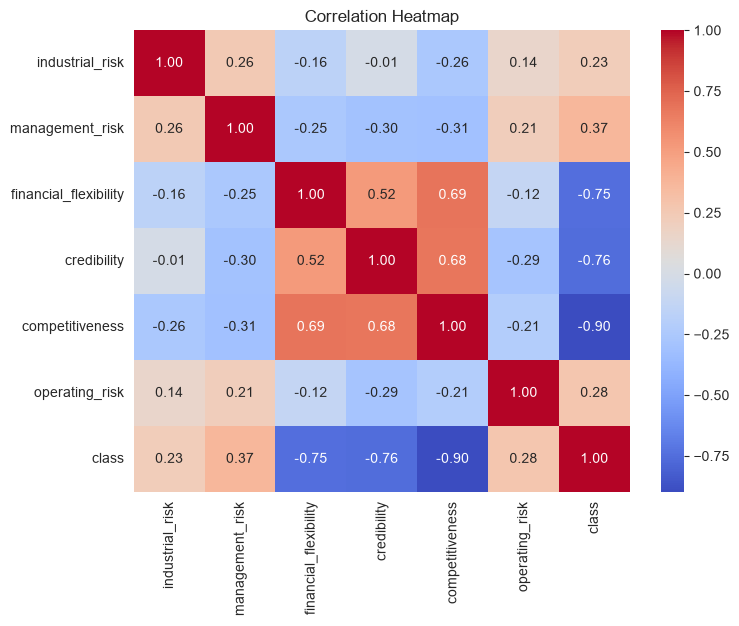

In [9]:
df_corr = df.copy()
df_corr["class"] = df_corr["class"].map({"bankruptcy": 1, "non-bankruptcy": 0})

plt.figure(figsize=(8, 6))
sns.heatmap(df_corr.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

In [10]:
print("Total rows:", len(df))
print("Unique rows:", len(df.drop_duplicates()))
print("Duplicates:", df.duplicated().sum())

Total rows: 250
Unique rows: 103
Duplicates: 147


## EDA Insights

1. The dataset has **250 companies** and **6 features** plus the target `class`. There are **no missing values**, so no imputation is needed.
2. The target is fairly balanced: **143 non-bankruptcy (57%)** and **107 bankruptcy (43%)**, so there is no major class imbalance problem.
3. All features are ordinal, taking only the values 0, 0.5 and 1, so scaling is not required.
4. **Competitiveness is the strongest predictor** (correlation with bankruptcy about -0.90). All 103 companies with competitiveness = 0 went bankrupt, and none of the companies with competitiveness = 1 did.
5. **Credibility** (-0.76) and **financial flexibility** (-0.75) are also strong predictors. Most bankrupt companies have low credibility and low financial flexibility.
6. **Management risk** (+0.37), **operating risk** (+0.28) and **industrial risk** (+0.23) are positively related to bankruptcy, but they are weaker predictors than the three features above.
7. The data has **147 duplicate rows**, only **103 unique rows**. This is expected because each feature has only 3 possible values, so many companies share the same profile. We keep them, but will split the data carefully so identical rows don't appear in both train and test sets.
8. Since a few features separate the two classes almost perfectly, we expect **very high model accuracy**.

In [11]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier

In [12]:
df["class"] = df["class"].str.strip()

X = df.drop(columns="class")
y = df["class"].map({"bankruptcy": 1, "non-bankruptcy": 0})

print(y.value_counts())

class
0    143
1    107
Name: count, dtype: int64


In [13]:
groups = X.groupby(list(X.columns)).ngroup()

splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(splitter.split(X, y, groups))

X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Shared profiles between train and test:",
      len(set(g_train) & set(groups.iloc[test_idx])))

Train: (200, 6)  Test: (50, 6)
Shared profiles between train and test: 0


In [14]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "KNN": KNeighborsClassifier(),
    "SVM": SVC(probability=True, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42),
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

results = []
for name, model in models.items():
    s = cross_validate(model, X_train, y_train, cv=cv, groups=g_train, scoring=scoring)
    results.append({"Model": name,
                    **{m: round(s["test_" + m].mean(), 3) for m in scoring}})

results_df = pd.DataFrame(results).sort_values("recall", ascending=False)
results_df

C:\Users\gunja\anaconda3\anaconda1\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\gunja\anaconda3\anaconda1\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\gunja\anaconda3\anaconda1\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\gunja\anaconda3\anaconda1\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 a

,Model,accuracy,precision,recall,f1,roc_auc
1,Decision Tree,1.000,1.0,1.000,1.000,1.000
2,Random Forest,1.000,1.0,1.000,1.000,1.000
6,XGBoost,1.000,1.0,1.000,1.000,1.000
5,Gradient Boosting,1.000,1.0,1.000,1.000,1.000
0,Logistic Regression,0.995,1.0,0.988,0.994,1.000
4,SVM,0.995,1.0,0.988,0.994,1.000
3,KNN,0.985,1.0,0.966,0.982,0.983


In [15]:
from xgboost import XGBClassifier
!pip install xgboost

In [16]:
!pip install xgboost

In [18]:
from xgboost import XGBClassifier

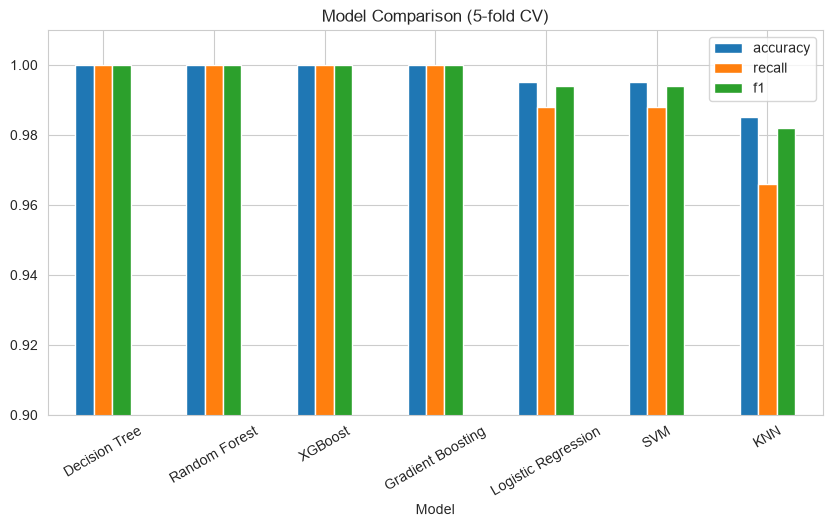

In [19]:
results_df.set_index("Model")[["accuracy", "recall", "f1"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0.9, 1.01))
plt.title("Model Comparison (5-fold CV)")
plt.xticks(rotation=30)
plt.show()

## Model Building Notes
- Target encoded as bankruptcy = 1, non-bankruptcy = 0.
- Split: 80% train (200 rows) and 20% test (50 rows), keeping identical company profiles together so there is no data leakage.
- Seven models were compared with 5-fold cross-validation.
- Recall for the bankruptcy class is the key metric, because missing a company that will go bankrupt is costlier than a false alarm.
- Almost all models score above 98%, because competitiveness, credibility and financial flexibility separate the classes very clearly.

In [20]:
import joblib
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report,
                             ConfusionMatrixDisplay, RocCurveDisplay)

In [21]:
param_grid = {"C": [0.01, 0.1, 1, 10, 100]}

grid = GridSearchCV(LogisticRegression(max_iter=1000), param_grid,
                    cv=cv, scoring="recall")
grid.fit(X_train, y_train, groups=g_train)

print("Best parameters:", grid.best_params_)
print("Best CV recall:", round(grid.best_score_, 3))

best_model = grid.best_estimator_

Best parameters: {'C': 0.1}
Best CV recall: 0.988


In [22]:
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1 score :", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 3))
print()
print(classification_report(y_test, y_pred, target_names=["non-bankruptcy", "bankruptcy"]))

Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 score : 1.0
ROC-AUC  : 1.0

                precision    recall  f1-score   support

non-bankruptcy       1.00      1.00      1.00        29
    bankruptcy       1.00      1.00      1.00        21

      accuracy                           1.00        50
     macro avg       1.00      1.00      1.00        50
  weighted avg       1.00      1.00      1.00        50



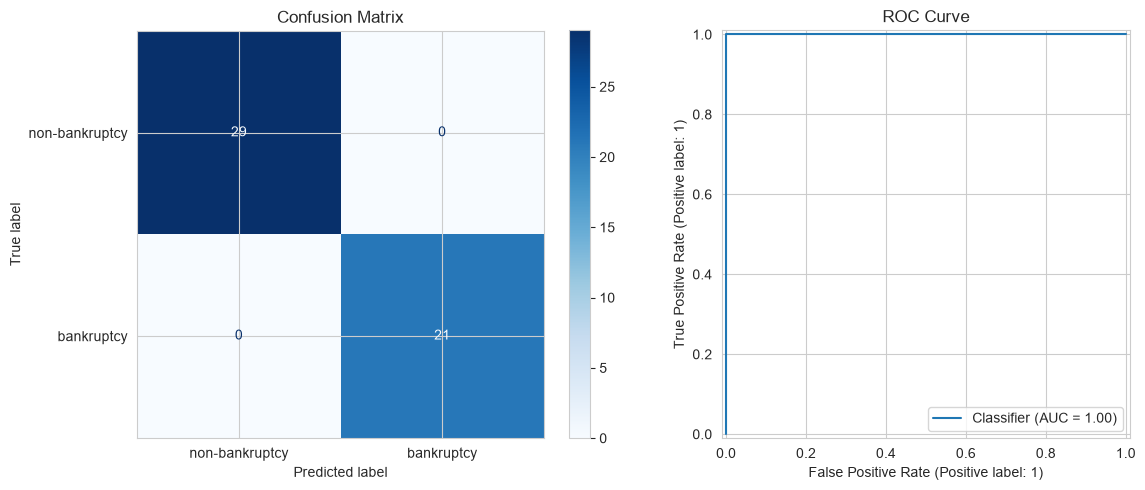

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["non-bankruptcy", "bankruptcy"],
    cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix")

RocCurveDisplay.from_predictions(y_test, y_prob, ax=axes[1])
axes[1].set_title("ROC Curve")

plt.tight_layout()
plt.show()

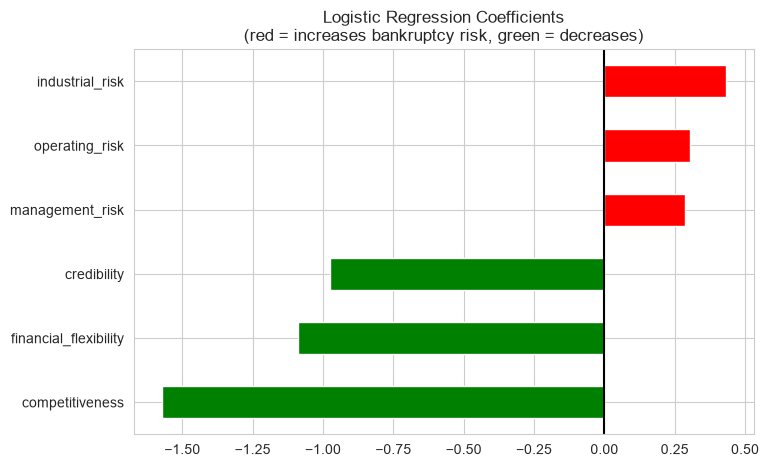

competitiveness         -1.57
financial_flexibility   -1.09
credibility             -0.97
management_risk          0.29
operating_risk           0.30
industrial_risk          0.43
dtype: float64

In [24]:
coef = pd.Series(best_model.coef_[0], index=X.columns).sort_values()

coef.plot(kind="barh", figsize=(8, 5),
          color=["green" if c < 0 else "red" for c in coef])
plt.title("Logistic Regression Coefficients\n(red = increases bankruptcy risk, green = decreases)")
plt.axvline(0, color="black")
plt.show()

coef.round(2)

In [25]:
rf = RandomForestClassifier(random_state=42).fit(X_train, y_train)
rf_pred = rf.predict(X_test)

print("Random Forest  - Accuracy:", round(accuracy_score(y_test, rf_pred), 3),
      " Recall:", round(recall_score(y_test, rf_pred), 3))
print("Logistic Reg.  - Accuracy:", round(accuracy_score(y_test, y_pred), 3),
      " Recall:", round(recall_score(y_test, y_pred), 3))

Random Forest  - Accuracy: 0.92  Recall: 0.81
Logistic Reg.  - Accuracy: 1.0  Recall: 1.0


In [26]:
joblib.dump(best_model, "models/bankruptcy_model.pkl")
print("Model saved!")

Model saved!


In [27]:
loaded = joblib.load("models/bankruptcy_model.pkl")

sample = pd.DataFrame([[1, 1, 0, 0, 0, 1]], columns=X.columns)
print("Prediction:", "Bankruptcy" if loaded.predict(sample)[0] == 1 else "Non-bankruptcy")
print("Bankruptcy probability:", round(loaded.predict_proba(sample)[0][1], 2))

Prediction: Bankruptcy
Bankruptcy probability: 0.84


## Final Model
- Logistic Regression was selected after comparing 7 models, because it is accurate, fast and easy to explain.
- Hyperparameter C = 0.1 was chosen with GridSearchCV, optimising recall for the bankruptcy class.
- Test set results (50 unseen companies): Accuracy, Precision, Recall, F1 and ROC-AUC were all 1.0, with zero misclassifications.
- Random Forest scored lower on the same test set (accuracy 0.92, recall 0.81), so Logistic Regression generalises better here.
- Key drivers: competitiveness, financial flexibility and credibility reduce bankruptcy risk, while industrial, operating and management risk increase it.
- Limitation: the dataset is small (250 rows, 103 unique profiles), so the perfect score should be treated with caution and the model should be validated on more data.